In [1]:
from forecast import load_prices, train_test_split_time
from battery import optimize_schedule, rule_based_schedule, schedule_revenue

prices = load_prices()
train, test = train_test_split_time(prices, test_weeks=8)
test_prices = test["price_eur_mwh"]

# "optimal" here means perfect-foresight: the LP is handed the ACTUAL realized prices,
# giving the revenue ceiling no real (forecast-driven) strategy could ever beat.
optimal_schedule = optimize_schedule(test_prices)
rule_schedule = rule_based_schedule(test_prices)

optimal_revenue = schedule_revenue(optimal_schedule, test_prices)
rule_revenue = schedule_revenue(rule_schedule, test_prices)

print(f"Perfect-foresight LP revenue: {optimal_revenue:,.2f} EUR")
print(f"Rule-based revenue:           {rule_revenue:,.2f} EUR")
print(f"LP improvement over rule-based: {100 * (optimal_revenue - rule_revenue) / rule_revenue:.1f}%")

Perfect-foresight LP revenue: 13,103.51 EUR
Rule-based revenue:           9,310.87 EUR
LP improvement over rule-based: 40.7%


In [2]:
# Sanity check, not just a headline number: the optimal schedule occasionally charges AND
# discharges in the same hour. battery.py's docstring explains why this can be genuinely
# optimal (never automatically assume a surprising result is a bug) - verify that claim here
# rather than just asserting it in a comment.
both_active = optimal_schedule[
    (optimal_schedule["charge_mwh"] > 0.001) & (optimal_schedule["discharge_mwh"] > 0.001)
]
contribution = test_prices.loc[both_active.index] * (
    both_active["discharge_mwh"] - both_active["charge_mwh"]
)

print(f"Hours with simultaneous charge+discharge: {len(both_active)} of {len(optimal_schedule)}")
print(f"All during negative prices: {(test_prices.loc[both_active.index] < 0).all()}")
print(f"All add positive value vs. not discharging: {(contribution > 0).all()}")
print(f"Total value from these hours: {contribution.sum():.2f} EUR "
      f"({100 * contribution.sum() / optimal_revenue:.2f}% of total revenue)")

Hours with simultaneous charge+discharge: 52 of 1344
All during negative prices: True
All add positive value vs. not discharging: True
Total value from these hours: 11.04 EUR (0.08% of total revenue)


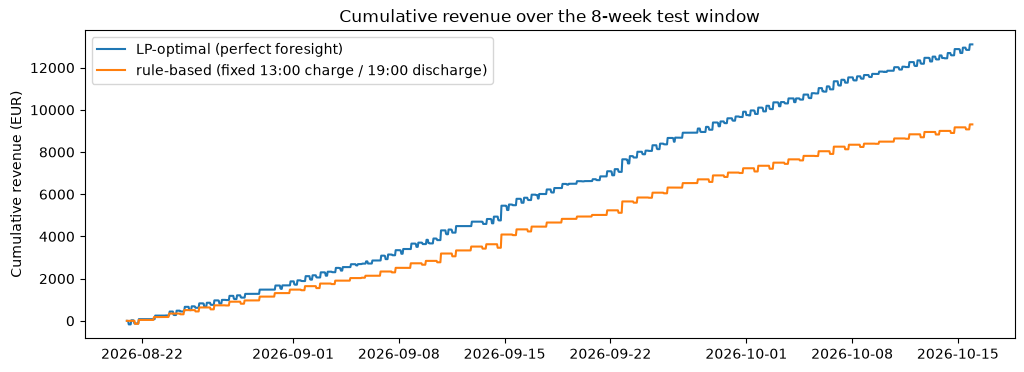

In [3]:
import matplotlib.pyplot as plt

optimal_hourly_profit = test_prices * (optimal_schedule["discharge_mwh"] - optimal_schedule["charge_mwh"])
rule_hourly_profit = test_prices * (rule_schedule["discharge_mwh"] - rule_schedule["charge_mwh"])

plt.figure(figsize=(12, 4))
plt.plot(optimal_hourly_profit.cumsum(), label="LP-optimal (perfect foresight)")
plt.plot(rule_hourly_profit.cumsum(), label="rule-based (fixed 13:00 charge / 19:00 discharge)")
plt.ylabel("Cumulative revenue (EUR)")
plt.legend()
plt.title("Cumulative revenue over the 8-week test window")
plt.show()

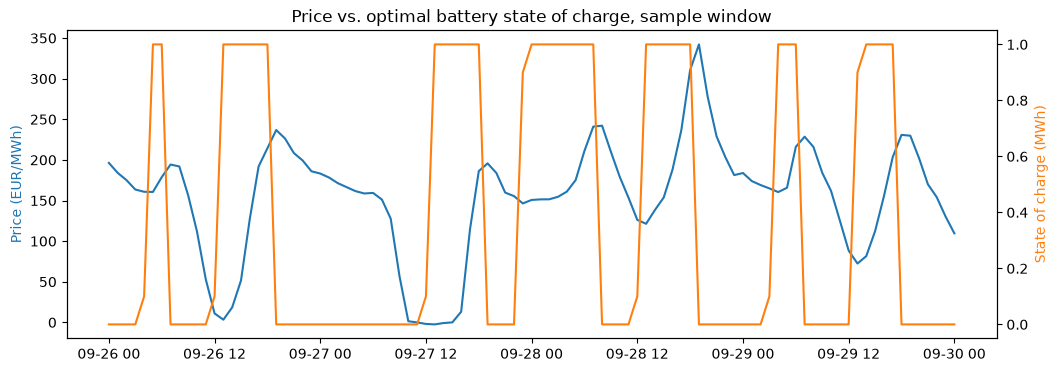

In [4]:
import pandas as pd

# A few real days: does the optimal schedule's state of charge actually track the price
# the way you'd expect - filling up when price dips, emptying when it spikes?
sample_start = test.index.min() + pd.Timedelta(days=36)
sample_end = sample_start + pd.Timedelta(days=4)

fig, price_axis = plt.subplots(figsize=(12, 4))
price_axis.plot(test_prices.loc[sample_start:sample_end], color="tab:blue")
price_axis.set_ylabel("Price (EUR/MWh)", color="tab:blue")

soc_axis = price_axis.twinx()
soc_axis.plot(optimal_schedule["soc_mwh"].loc[sample_start:sample_end], color="tab:orange")
soc_axis.set_ylabel("State of charge (MWh)", color="tab:orange")

plt.title("Price vs. optimal battery state of charge, sample window")
plt.show()